# 02 — Validación del modelo (Fase 2)

Cartera sintética de la **Compañía de Seguros Cordillera (ficticia)**, corte 31-12-2025. Este notebook valida el modelo
de la Fase 2 contra la verdad del generador (`data/truth/`), algo que el pipeline de tarificación nunca lee:

1. IBNR (chain-ladder y Cape Cod) contra el IBNR verdadero.
2. Tendencia: Fase 1, dos etapas y generador.
3. Relatividades recuperadas.
4. Validación fuera de tiempo 2025: línea base, dos etapas y Tweedie.
5. Credibilidad Bühlmann-Straub.
6. Detección de los 5 patrones plantados.
7. Reajuste 2026 y su descomposición.

Requiere haber corrido `python -m colectivos.pipeline` y `python -m colectivos.validation --data data`.
Cada gráfico va con su tabla: la tabla es la vista accesible del dato.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from colectivos.config import CLAIM_TYPES as CLAIM_TYPE_TUPLE, load_pricing_config
from colectivos.models.glm import fit_all
from colectivos.models.ibnr import cdf_to_ultimate, development_factors
from colectivos.models.oot import _expected_by_row
from colectivos.models.tweedie import fit_tweedie
from colectivos.models.two_stage import fit_two_stage
from colectivos.models.ultimates import cells_to_ultimate, to_yearly

CLAIM_TYPES = list(CLAIM_TYPE_TUPLE)
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
DATA = PROJECT_ROOT / 'data'
VALIDATION = DATA / 'reports' / 'validacion'
con = duckdb.connect(str(DATA / 'warehouse.duckdb'), read_only=True)
pricing = load_pricing_config(PROJECT_ROOT / 'config' / 'pricing.yaml')
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.width', 160)

# Paleta categórica validada (orden fijo de slots, nunca rotado); superficie y tintas de texto.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
POSITIVE, NEGATIVE, NEUTRAL = '#2a78d6', '#e34948', '#8a8984'
SURFACE, INK, INK_2 = '#fcfcfb', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'text.color': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'lines.linewidth': 2, 'lines.markersize': 6, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False,
    'figure.figsize': (9, 4.2), 'figure.dpi': 110,
})

def pct(ax, axis='y'):
    fmt = plt.FuncFormatter(lambda v, _: f'{v:.0%}')
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(fmt)

def log_axis(axis, ticks):
    axis.set_major_locator(plt.FixedLocator(ticks))
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.10g}'.replace(',', '.')))
    axis.set_minor_formatter(plt.NullFormatter())

def grouped_bars(ax, frame, columns, labels, width=0.8):
    n = len(columns)
    x = np.arange(len(frame))
    bar = width / n
    for i, (column, label) in enumerate(zip(columns, labels)):
        ax.bar(x + (i - (n - 1) / 2) * bar, frame[column], bar * 0.92, color=SERIES[i], label=label)
    ax.set_xticks(x, frame.index)

## 1. IBNR

In [2]:
ibnr = con.execute('SELECT * FROM marts.mart_ibnr').df()
ibnr['year'] = pd.to_datetime(ibnr.origin_quarter).dt.year
ibnr.groupby('year')[['paid_uf', 'ultimate_uf', 'ibnr_uf']].sum()

,paid_uf,ultimate_uf,ibnr_uf
year,,,
2021,"411,228.5942","411,228.5942",0.0000
2022,"429,102.9374","429,189.7947",86.8573
2023,"437,766.4874","438,234.1372",467.6497
2024,"515,009.5068","517,789.4464","2,779.9396"
2025,"490,552.7844","570,996.3767","80,443.5923"


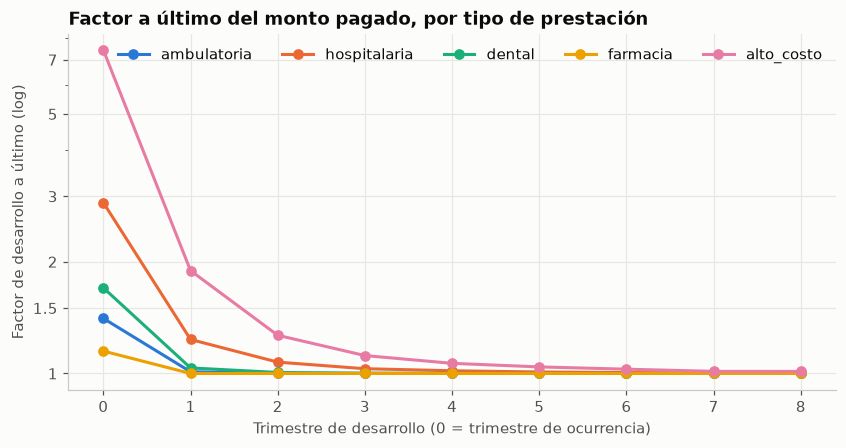

,ambulatoria,hospitalaria,dental,farmacia,alto_costo
dev_quarter,,,,,
0,1.4070,2.8850,1.7010,1.1490,7.4340
1,1.0110,1.2350,1.0350,1.0000,1.8920
2,1.0010,1.0730,1.0060,1.0000,1.2670
3,1.0000,1.0300,1.0020,1.0000,1.1170
4,1.0000,1.0170,1.0010,1.0000,1.0650
5,1.0000,1.0090,1.0000,1.0000,1.0420
6,1.0000,1.0060,1.0000,1.0000,1.0270
7,1.0000,1.0030,1.0000,1.0000,1.0130
8,1.0000,1.0020,1.0000,1.0000,1.0130


In [3]:
development = con.execute('SELECT * FROM marts.mart_development_quarterly').df()
cdf = pd.DataFrame({
    claim_type: cdf_to_ultimate(development_factors(triangle, 'paid_uf_cum'))
    for claim_type, triangle in development.groupby('claim_type')
}).loc[:8, CLAIM_TYPES]

fig, ax = plt.subplots()
for i, claim_type in enumerate(CLAIM_TYPES):
    ax.plot(cdf.index, cdf[claim_type], color=SERIES[i], marker='o', label=claim_type)
ax.set_yscale('log')
log_axis(ax.yaxis, [1, 1.5, 2, 3, 5, 7])
ax.set_xlabel('Trimestre de desarrollo (0 = trimestre de ocurrencia)')
ax.set_ylabel('Factor de desarrollo a último (log)')
ax.set_title('Factor a último del monto pagado, por tipo de prestación')
ax.legend(ncols=5, loc='upper right')
plt.show()
cdf.round(3)

Alto costo es el único tipo con desarrollo largo: un trimestre recién ocurrido se multiplica por ~7. Por eso su monto de
2025 usa Cape Cod (a priori del propio triángulo) en vez de chain-ladder puro. Desde el trimestre 8 todos los factores
quedan a ±0,5% de 1, lo que respalda la cola = 1.

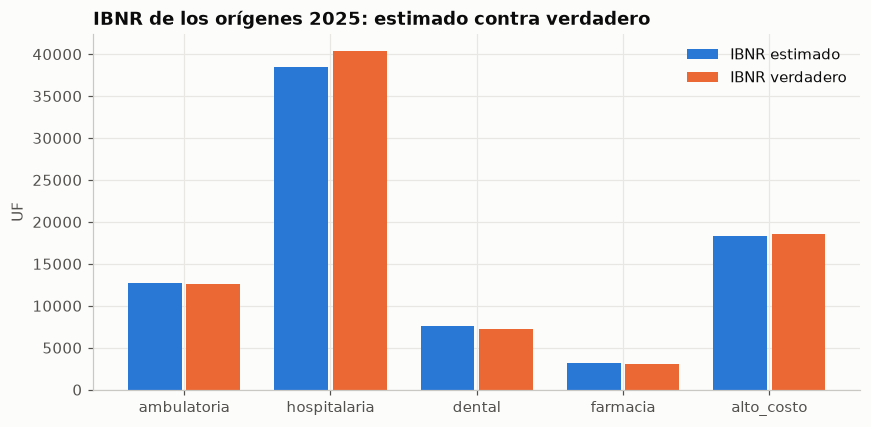

,claim_type,year,ibnr_est_uf,ibnr_true_uf,error_uf,error_rel
0,alto_costo,2024,"1,419.8575",628.8861,790.9714,1.2577
1,alto_costo,2025,"18,377.6483","18,545.9777",-168.3294,-0.0091
2,ambulatoria,2024,4.9562,3.9444,1.0119,0.2565
3,ambulatoria,2025,"12,765.7019","12,572.3565",193.3454,0.0154
4,dental,2024,19.9159,13.7054,6.2104,0.4531
5,dental,2025,"7,599.0374","7,275.8780",323.1594,0.0444
6,farmacia,2024,0.0000,0.0000,-0.0000,-1.0000
7,farmacia,2025,"3,209.2305","3,068.9458",140.2847,0.0457
8,hospitalaria,2024,"1,335.2100","1,418.9334",-83.7233,-0.0590
9,hospitalaria,2025,"38,491.9743","40,387.3685","-1,895.3941",-0.0469


In [4]:
errors = pd.read_csv(VALIDATION / 'ibnr_error_by_year.csv')
errors_2025 = errors[errors.year == 2025].set_index('claim_type').loc[CLAIM_TYPES]
fig, ax = plt.subplots()
grouped_bars(ax, errors_2025, ['ibnr_est_uf', 'ibnr_true_uf'], ['IBNR estimado', 'IBNR verdadero'])
ax.set_ylabel('UF')
ax.set_title('IBNR de los orígenes 2025: estimado contra verdadero')
ax.legend()
plt.show()
errors.assign(error_rel=errors.error_uf / errors.ibnr_true_uf.where(errors.ibnr_true_uf > 0))

El IBNR total de 2025 queda ~1,7% bajo el verdadero; el mayor desvío en UF está en hospitalaria (~−5%). El error que
el IBNR aporta a la validación fuera de tiempo es chico: `ae_shift` (sección 4) se mueve entre −0,5 y +1,2 puntos.

## 2. Tendencia: Fase 1, dos etapas y generador

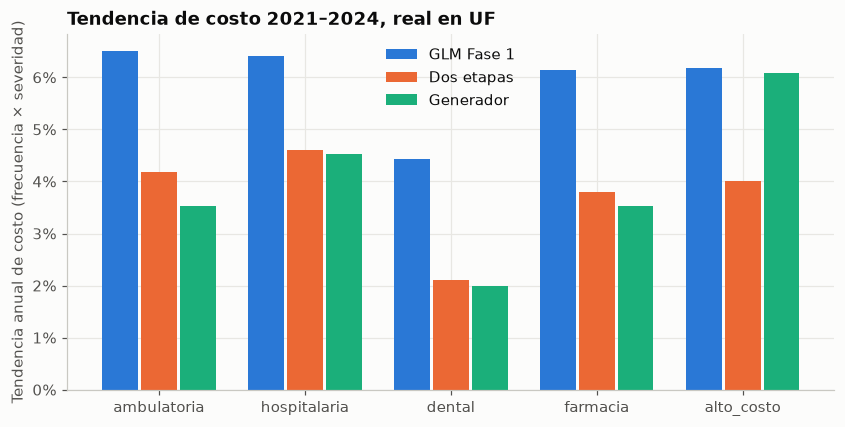

,fase_1,dos_etapas,generador
ambulatoria,0.0651,0.0417,0.0353
hospitalaria,0.0641,0.0459,0.0454
dental,0.0444,0.0212,0.0200
farmacia,0.0615,0.0381,0.0353
alto_costo,0.0617,0.0401,0.0608


In [5]:
paid_cells = con.execute('SELECT * FROM marts.mart_model_cells').df()
phase1 = fit_all(paid_cells, train_years=tuple(pricing.train_years_oot))
phase1_total = {ct: np.exp(m.freq.params['year_c'] + m.sev.params['year_c']) - 1 for ct, m in phase1.items()}
trends = pd.read_csv(VALIDATION / 'trend_recovery.csv')
trends = trends[trends.train_years == str(tuple(pricing.train_years_oot))].set_index('claim_type').loc[CLAIM_TYPES]
trend_table = pd.DataFrame({
    'fase_1': pd.Series(phase1_total),
    'dos_etapas': trends.total_est,
    'generador': trends.total_true,
}).loc[CLAIM_TYPES]

fig, ax = plt.subplots()
grouped_bars(ax, trend_table, ['fase_1', 'dos_etapas', 'generador'], ['GLM Fase 1', 'Dos etapas', 'Generador'])
pct(ax)
ax.set_ylabel('Tendencia anual de costo (frecuencia × severidad)')
ax.set_title('Tendencia de costo 2021–2024, real en UF')
ax.legend()
plt.show()
trend_table

La Fase 1 lee como tendencia la entrada de clientes más riesgosos en 2024, y sobreestima. La etapa 1 de dos etapas
estima la tendencia dentro de cada empresa (efecto fijo) y queda cerca del generador. En alto costo queda bajo el
generador porque el tope anual de 1500 UF y el umbral de siniestro grande amortiguan la severidad.

## 3. Relatividades contra la verdad

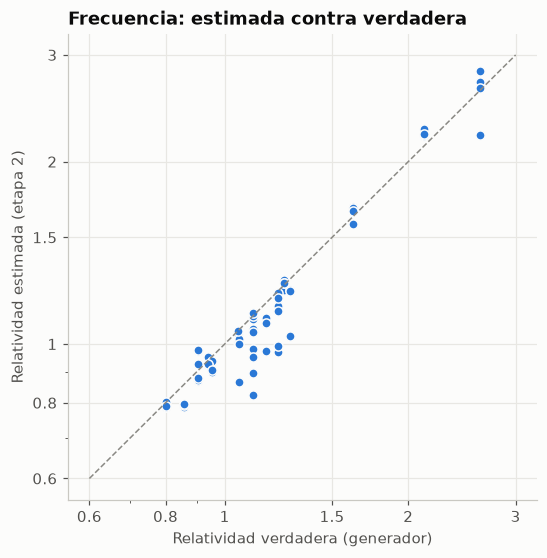

Sector público / retail: estimado 1.22, verdadero 1,21, Fase 1 1,52


factor
age_band        0.0342
health_system   0.0156
industry        0.0946
region          0.0572
role            0.0087
sex             0.0113
Name: error_rel_medio, dtype: float64

In [6]:
relativities = pd.read_csv(VALIDATION / 'relativity_recovery.csv')
shown = relativities[(relativities.claim_type != 'alto_costo') & (relativities.level != relativities.base_level)]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(shown.true, shown.estimated, s=36, color=SERIES[0], edgecolor=SURFACE, linewidth=1)
limits = [0.6, 3.0]
ax.plot(limits, limits, color=NEUTRAL, linewidth=1, linestyle='--')
ax.set_xscale('log'); ax.set_yscale('log')
for axis in (ax.xaxis, ax.yaxis):
    log_axis(axis, [0.6, 0.8, 1, 1.5, 2, 3])
ax.set_xlabel('Relatividad verdadera (generador)')
ax.set_ylabel('Relatividad estimada (etapa 2)')
ax.set_title('Frecuencia: estimada contra verdadera')
plt.show()
ambulatoria = relativities[relativities.claim_type == 'ambulatoria'].set_index('level')
public_vs_retail = ambulatoria.estimated['sector_publico'] / ambulatoria.estimated['retail']
print(f'Sector público / retail: estimado {public_vs_retail:.2f}, verdadero 1,21, Fase 1 1,52')
shown.groupby('factor').apply(lambda d: (d.estimated / d.true - 1).abs().mean(), include_groups=False).rename('error_rel_medio')

Edad, sexo, rol, previsión y región quedan cerca de la diagonal. Los rubros quedan algo bajo la verdad, porque el
efecto empresa (que la etapa 2 no modela) se mezcla con el rubro. Aun así, sector público / retail sale ~1,22 contra
1,21 verdadero, frente al 1,52 de la Fase 1. En hospitalaria, los rubros relativos a construcción salen bajos porque el
nivel de construcción incluye su tendencia plantada (×1,08 por año), que `parameters.json` no cuenta.

## 4. Validación fuera de tiempo 2025

In [7]:
con.execute('SELECT * FROM marts.mart_oot_contract').df()

,model,gini,rmse_per_py,ae
0,baseline,0.0337,4.4858,1.0043
1,two_stage,0.0353,4.5126,1.0584
2,tweedie,0.0438,4.4861,1.0552


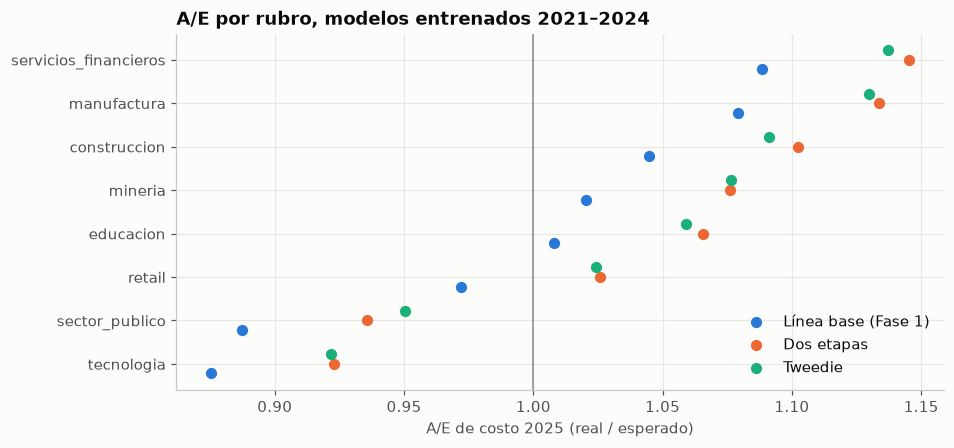

model,baseline,two_stage,tweedie
level,,,
tecnologia,0.8754,0.9229,0.9217
sector_publico,0.8872,0.9357,0.9504
retail,0.9720,1.0256,1.0241
educacion,1.0078,1.0657,1.0589
mineria,1.0205,1.0761,1.0763
construccion,1.0448,1.1025,1.0910
manufactura,1.0793,1.1338,1.1296
servicios_financieros,1.0885,1.1452,1.1371


In [8]:
segments = con.execute("SELECT * FROM marts.mart_oot_by_segment WHERE factor = 'industry'").df()
industry = segments.pivot(index='level', columns='model', values='ae')[['baseline', 'two_stage', 'tweedie']]
industry = industry.sort_values('two_stage')
fig, ax = plt.subplots()
y = np.arange(len(industry))
for i, (model, label) in enumerate([('baseline', 'Línea base (Fase 1)'), ('two_stage', 'Dos etapas'), ('tweedie', 'Tweedie')]):
    ax.scatter(industry[model], y + (i - 1) * 0.22, color=SERIES[i], s=40, label=label, zorder=3)
ax.axvline(1, color=NEUTRAL, linewidth=1)
ax.set_yticks(y, industry.index)
ax.set_xlabel('A/E de costo 2025 (real / esperado)')
ax.set_title('A/E por rubro, modelos entrenados 2021–2024')
ax.legend(loc='lower right')
plt.show()
industry

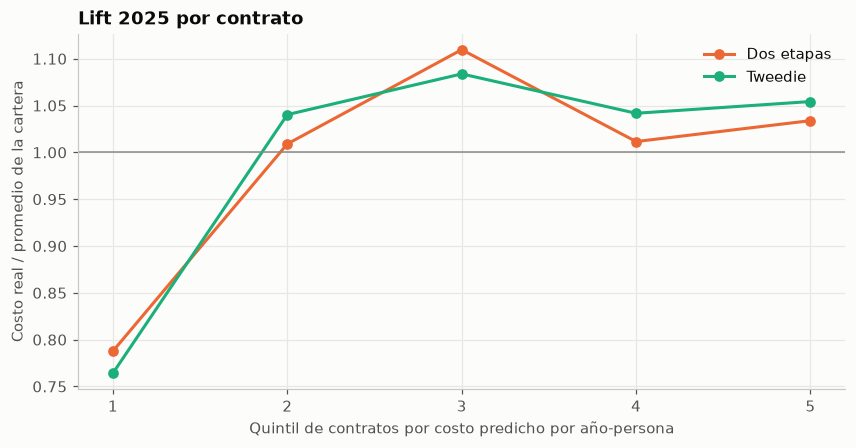

,dos_etapas,tweedie
quintile,,
1,0.7878,0.7643
2,1.0090,1.0403
3,1.1097,1.0838
4,1.0115,1.0417
5,1.0339,1.0543


In [9]:
company_cells = con.execute('SELECT * FROM marts.mart_model_cells_company').df()
cells_yearly = to_yearly(cells_to_ultimate(company_cells, ibnr.drop(columns='year')))
champion = fit_two_stage(cells_yearly, tuple(pricing.train_years_oot), pricing)
challenger = fit_tweedie(cells_yearly, tuple(pricing.train_years_oot), champion.trends, tuple(pricing.tweedie_powers))
test = cells_yearly[(cells_yearly.year == 2025) & (cells_yearly.exposure_years > 0)].reset_index(drop=True)

def lift(model) -> pd.Series:
    rows = _expected_by_row(model, test, 2.0)
    contracts = rows.groupby('contract_id')[['reimbursed_capped_ult_uf', 'expected_uf']].sum()
    contracts['exposure'] = rows[rows.claim_type == 'ambulatoria'].groupby('contract_id').exposure_years.sum()
    contracts = contracts[contracts.exposure > 0]
    contracts['quintile'] = pd.qcut((contracts.expected_uf / contracts.exposure).rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
    by_quintile = contracts.groupby('quintile', observed=True)[['reimbursed_capped_ult_uf', 'exposure']].sum()
    portfolio = contracts.reimbursed_capped_ult_uf.sum() / contracts.exposure.sum()
    return by_quintile.reimbursed_capped_ult_uf / by_quintile.exposure / portfolio

lift_table = pd.DataFrame({'dos_etapas': lift(champion), 'tweedie': lift(challenger)})
fig, ax = plt.subplots()
for i, (column, label) in enumerate([('dos_etapas', 'Dos etapas'), ('tweedie', 'Tweedie')]):
    ax.plot(lift_table.index.astype(int), lift_table[column], color=SERIES[i + 1], marker='o', label=label)
ax.axhline(1, color=NEUTRAL, linewidth=1)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel('Quintil de contratos por costo predicho por año-persona')
ax.set_ylabel('Costo real / promedio de la cartera')
ax.set_title('Lift 2025 por contrato')
ax.legend()
plt.show()
lift_table

In [10]:
pd.read_csv(VALIDATION / 'oot_truth_by_type.csv')[['model', 'claim_type', 'ae', 'ae_shift']]

,model,claim_type,ae,ae_shift
0,baseline,alto_costo,1.0466,0.0035
1,baseline,ambulatoria,1.0054,-0.0011
2,baseline,dental,1.0051,-0.0048
3,baseline,farmacia,1.0153,-0.0013
4,baseline,hospitalaria,0.9922,0.0113
5,two_stage,alto_costo,1.1427,0.0039
6,two_stage,ambulatoria,1.0611,-0.0011
7,two_stage,dental,1.0620,-0.0051
8,two_stage,farmacia,1.0721,-0.0014
9,two_stage,hospitalaria,1.0318,0.0118


In [11]:
# Regla de decisión 5.5: diferencia de Gini retador − campeón, remuestreando contratos (1.000 réplicas, IC 90%).
con.execute('SELECT * FROM marts.mart_oot_gini_bootstrap').df().T

,0
champion,two_stage
challenger,tweedie
gini_champion,0.0353
gini_challenger,0.0438
diff_mean,0.0075
diff_low,-0.0009
diff_high,0.0189
p_challenger_better,0.9160
n_boot,"1,000.0000"


El modelo de dos etapas y el Tweedie subestiman 2025 en ~6% (A/E ~1,06): los clientes que entran en 2024 son más
riesgosos (efecto empresa medio 1,00 → 1,06) y ninguno de los dos modela la empresa; la línea base acierta en total
solo porque su tendencia inflada absorbe ese mix. El lift es bajo y parecido en ambos: el costo por contrato está
dominado por el efecto empresa, que corrige la credibilidad (sección 5). El Tweedie tiene un Gini algo mayor, pero el
intervalo bootstrap de la diferencia (tabla de arriba) incluye 0 y su A/E por segmento no es mejor: tarifica el modelo de dos etapas
(regla 5.5 del spec). `ae_shift` es el error que aporta el IBNR (A/E contra la verdad − contra los últimos estimados).

## 5. Credibilidad Bühlmann-Straub

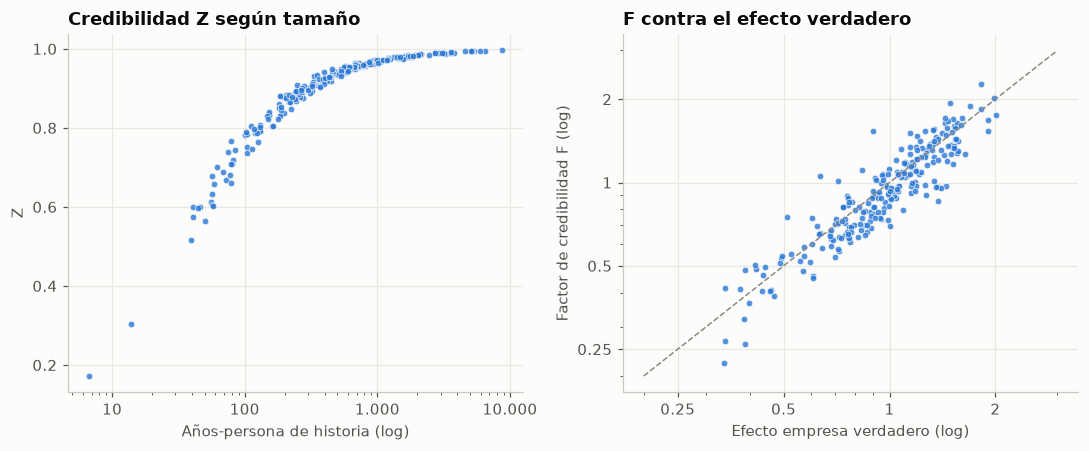

,metric,model_only,with_credibility
0,rmse_per_py,4.6611,2.0141
1,ae,1.0610,0.9948
2,corr_log_factor_log_effect,NaN,0.9015


,metric,value
0,corr_log_rate_change_log_effect,0.0272
1,n_contracts,245.0000


In [12]:
renewal = con.execute('SELECT * FROM marts.mart_renewal_2026').df()
effects = pd.read_parquet(DATA / 'truth' / 'company_effects.parquet').set_index('company_id').company_effect
renewal['company_effect'] = renewal.company_id.map(effects)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2))
left.scatter(renewal.exposure_years_hist, renewal.credibility_z, s=18, color=SERIES[0], alpha=0.8, edgecolor=SURFACE, linewidth=0.5)
left.set_xscale('log')
log_axis(left.xaxis, [10, 100, 1000, 10000])
left.set_xlabel('Años-persona de historia (log)')
left.set_ylabel('Z')
left.set_title('Credibilidad Z según tamaño')
right.scatter(renewal.company_effect, renewal.credibility_factor, s=18, color=SERIES[0], alpha=0.8, edgecolor=SURFACE, linewidth=0.5)
right.set_xscale('log'); right.set_yscale('log')
for axis in (right.xaxis, right.yaxis):
    log_axis(axis, [0.25, 0.5, 1, 2])
right.plot([0.2, 3], [0.2, 3], color=NEUTRAL, linewidth=1, linestyle='--')
right.set_xlabel('Efecto empresa verdadero (log)')
right.set_ylabel('Factor de credibilidad F (log)')
right.set_title('F contra el efecto verdadero')
plt.tight_layout()
plt.show()
display(pd.read_csv(VALIDATION / 'credibility_gain.csv'))
pd.read_csv(VALIDATION / 'rate_change_vs_effect.csv')

Z crece con el tamaño del contrato (k ≈ 300 UF de costo esperado) y F sigue al efecto empresa verdadero sin haberlo
visto. Con modelo y credibilidad estimados en 2021–2024, el error por año-persona contra el costo real de 2025 baja a
menos de la mitad y el A/E de la cartera pasa de ~1,06 a ~1,00. La correlación entre el reajuste requerido y el efecto
empresa verdadero queda en ~0 (Fase 1: −0,90): el reajuste ya no depende de qué tan riesgosa es la empresa por
razones que el modelo no veía.

## 6. Patrones plantados

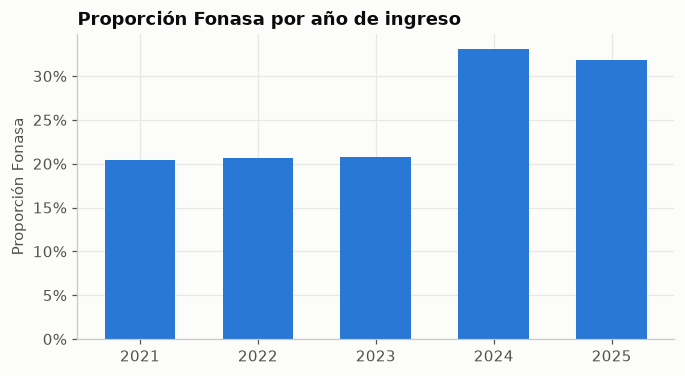

,pattern,detected,evidence
0,industry_hospital_trend,True,"tendencias adicionales retenidas {""construccion"": 0.0498}, p LR = 0.0008609741872524985"
1,adverse_selection,True,"A/E cohorte ≥2023 / cohorte anterior en empresas chicas: plantadas 1.578, resto 1.001"
2,catastrophic_event,True,"6 siniestros sobre el umbral; el catastrófico aparece con 8,000 UF y exceso 6,500 UF fuera de la experiencia"
3,inadequate_rate_changes,True,reajuste requerido mediano: sin reajuste +35.7% vs resto +14.4%; 54% de los contratos sin reajuste en el cuartil superior (35 contratos)
4,fonasa_shift,True,"proporción Fonasa por año de ingreso: 2021 20.4%, 2022 20.6%, 2023 20.8%, 2024 33.1%, 2025 31.8%"


In [13]:
fonasa = con.execute('''
    SELECT
        YEAR(enrollment_date) AS enrollment_year,
        AVG(CASE WHEN health_system = 'fonasa' THEN 1.0 ELSE 0.0 END) AS fonasa_share
    FROM staging.stg_insureds
    WHERE YEAR(enrollment_date) >= 2021
    GROUP BY ALL
    ORDER BY enrollment_year
''').df().set_index('enrollment_year')
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(fonasa.index.astype(str), fonasa.fonasa_share, 0.6, color=SERIES[0])
pct(ax)
ax.set_ylabel('Proporción Fonasa')
ax.set_title('Proporción Fonasa por año de ingreso')
plt.show()
with pd.option_context('display.max_colwidth', 200):
    display(pd.read_csv(VALIDATION / 'pattern_detection.csv'))

Los cinco patrones aparecen con criterios que no miran la verdad (la verdad solo dice dónde estaban). La tendencia de
construcción en hospitalaria solo se detecta al sumar 2025: con 2021–2024 el efecto queda tapado por el ruido
(~900 siniestros al año en ~35 empresas).

## 7. Reajuste 2026 y descomposición

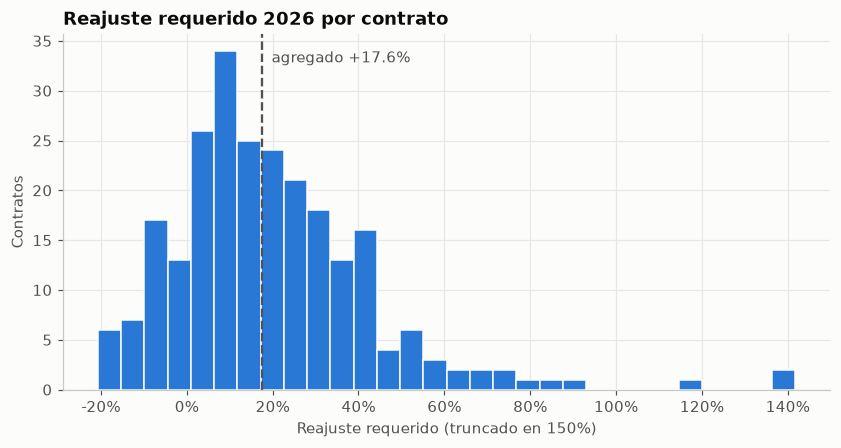

count   245.0000
mean      0.2000
std       0.2382
min      -0.2069
10%      -0.0547
50%       0.1592
90%       0.4436
max       1.4179
Name: required_rate_change, dtype: float64

In [14]:
aggregate = renewal.technical_premium_annual_uf.sum() / renewal.current_premium_annual_uf.sum() - 1
fig, ax = plt.subplots()
ax.hist(renewal.required_rate_change.clip(upper=1.5), bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=1)
ax.axvline(aggregate, color=INK_2, linewidth=1.5, linestyle='--')
ax.annotate(f'agregado {aggregate:+.1%}', (aggregate, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords='offset points', color=INK_2)
pct(ax, 'x')
ax.set_xlabel('Reajuste requerido (truncado en 150%)')
ax.set_ylabel('Contratos')
ax.set_title('Reajuste requerido 2026 por contrato')
plt.show()
renewal.required_rate_change.describe(percentiles=[0.1, 0.5, 0.9])

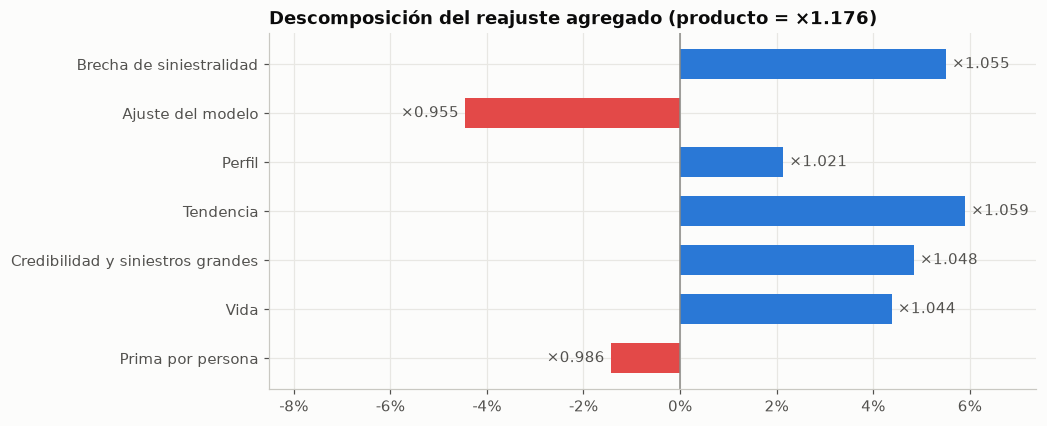

,factor,multiplier,log_share
0,Brecha de siniestralidad,1.0551,0.3302
1,Ajuste del modelo,0.9555,-0.2804
2,Perfil,1.0214,0.1302
3,Tendencia,1.0590,0.3532
4,Credibilidad y siniestros grandes,1.0484,0.2913
5,Vida,1.0439,0.2644
6,Prima por persona,0.9857,-0.0889


In [15]:
decomposition = con.execute('SELECT * FROM marts.mart_rate_change_decomposition').df()
change = decomposition.multiplier - 1
fig, ax = plt.subplots()
y = np.arange(len(decomposition))[::-1]
ax.barh(y, change, 0.6, color=np.where(change >= 0, POSITIVE, NEGATIVE))
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_xlim(min(change.min(), 0) * 1.8 - 0.005, max(change.max(), 0) * 1.25)
ax.set_yticks(y, decomposition.factor)
for yi, value in zip(y, change):
    ax.annotate(f'×{1 + value:.3f}', (value, yi), xytext=(4 if value >= 0 else -4, 0), textcoords='offset points',
                ha='left' if value >= 0 else 'right', va='center', color=INK_2)
pct(ax, 'x')
ax.set_title(f'Descomposición del reajuste agregado (producto = ×{decomposition.multiplier.prod():.3f})')
plt.show()
decomposition

La descomposición telescopea: el producto de los factores es exactamente prima técnica / prima vigente. "Ajuste del
modelo" (<1) y "Credibilidad y siniestros grandes" (>1) son dos caras del mismo fenómeno: los clientes de 2025 son más
riesgosos que el promedio con que se entrenó el modelo, y la credibilidad lo devuelve contrato a contrato.